# Decomposing a Dyn-Bench question, step by step

A Dyn-Bench question is not one problem. *"Do the two people get closer or farther apart?"*
is: which two people (grounding), where each one is in 3D at every moment (measurement),
how the distance between them behaves (reduction), and which option says that
(interpretation). This notebook takes one question of a chosen kind and shows each of those
sub-problems being solved, then assembled into the answer.

```mermaid
flowchart TD
  IN([video · question · options]) --> S0["<b>S0 · CLIP CONTEXT</b> (once per clip)<br/>generator frames + time axis<br/>Point4D scene pass: camera R,t,K · depth<br/>gravity · scale (relative + metric)"]
  S0 --> S1["<b>S1 · DECOMPOSE</b> → Query Program"]
  S1 --> D0{"D0 · option form?<br/>vocabulary · atoms · number · count · order · narrative"}
  D0 --> D1{"D1 · does geometry, time or<br/>visibility decide it?"}
  D1 -- "no: semantic" --> LC(["LEAF C · Qwen answers from the frames"])
  D1 -- yes --> SL["fill the kind's slots<br/>D2 WHO · D3 WHEN · D4 WHAT+FRAME · D5 REDUCE"]
  SL --> S2["<b>S2 · GROUND</b> each role with SAM3<br/>entity · group · category · main subject · landmark"]
  S2 --> S3["<b>S3 · MEASURE</b><br/>lift masks through Point4D depth → signal in a frame and window<br/>→ reduce (value · noise floor · confidence)"]
  S3 --> S4["<b>S4 · INTERPRET</b> · score every option's claim"]
  S4 --> D7{"D7 · this kind's gate:<br/>clear margin and every claim checkable?"}
  D7 -- yes --> LA(["LEAF A · deterministic answer"])
  D7 -- no --> LB(["LEAF B · Qwen sees the frames + the measured evidence<br/>(frames only, for kinds where evidence did not help on dev)"])
  LA --> OUT([answer + trace])
  LB --> OUT
  LC --> OUT
  classDef leaf fill:#dff3e4,stroke:#3a7,stroke-width:1px;
  class LA leaf;
```

<details><summary>The same graph as text (for frontends without Mermaid)</summary>

```
video · question · options
  └─ S0 CLIP CONTEXT   generator frames + time axis · Point4D scene pass (camera R,t,K · depth) · gravity · scale
      └─ S1 DECOMPOSE  question + options → Query Program (kind first, then slots)
          ├─ D0 option form?  vocabulary | atoms | number | count | order | narrative
          ├─ D1 does geometry / time / visibility decide it?  ── no ──► LEAF C  Qwen answers from the frames
          └─ yes: D2 WHO · D3 WHEN · D4 WHAT+FRAME · D5 REDUCE
              └─ S2 GROUND    SAM3: entity | group | category | main subject | landmark
                  └─ S3 MEASURE   lift masks through Point4D depth → signal in a frame and window → reduce
                      └─ S4 INTERPRET   score every option's claim against the measurement
                          └─ D7 this kind's gate: clear margin and every claim checkable?
                                ├─ yes ─► LEAF A  deterministic answer
                                └─ no  ─► LEAF B  Qwen sees the frames + the evidence
```

</details>

**Six choices make a program.** A *kind* is a program template; the question fills its slots.

| axis | what it decides | examples |
|---|---|---|
| WHO | which entities are involved | the camera · one object · a group ("the two men") · a category (count) · the implicit *main subject* · a landmark |
| WHEN | which part of the clip | whole · `[t0, t1]` seconds · an instant · a phase (first 25%) · between two events |
| WHAT | the signal | camera motion · range · displacement · instances · event onset · mask-to-region distance |
| FRAME | reference frame | world (first camera) · camera-at-t · gravity-levelled · image · *the generator's convention* |
| REDUCE | signal → answer | net · trend shape · direction words · value at t · count · order |
| OPTIONS | what each option claims | a vocabulary entry · direction words · a number · a count · an event order · a narrative |

**Reading the tree.** grey = not yet solved · green = solved by a measurement · amber = fell
back to Qwen with the evidence · red = could not be solved · blue = no measurement can decide it.

**Where the numbers come from.** Every model output was produced ahead of time on a GPU
(`scripts/run_decomposition_prep_a100.slurm`): Point4D (camera, depth, 3D), SAM3 (grounding),
DA3-Nested (metric scale), Qwen3-VL-8B (reading the question, naming the main subject, and the
leaf-B/C answers). This notebook is CPU-only and reads those artifacts.

**Reading it honestly.** Units are Point4D's own unless a metre value is shown, with its scale
uncertainty. Thresholds ("noticeable pan", "stable distance") are conventions of the benchmark's
question generator; they are named constants in `measure.TUNING` and `interpret.DECISION`, and the
calibration study varies them on a dev split of clips.


## Select a question

One branch of the decision graph, one example of it. Everything below re-runs for the selection; change `KIND` / `PICK` and run all.

In [14]:
import sys, json, warnings
from pathlib import Path
REPO = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "dyn_dataset_exploration").is_dir())
sys.path.insert(0, str(REPO))

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from dyn_dataset_exploration.decomposition import interpret, measure, pipeline, scene4d, viz
from dyn_dataset_exploration.decomposition import program as P

warnings.filterwarnings("ignore", category=RuntimeWarning)
np.set_printoptions(precision=3, suppress=True)
plt.rcParams.update({"figure.dpi": 100, "figure.facecolor": "white", "axes.grid": True,
                     "grid.alpha": 0.22, "font.size": 9})

# ---- choose a question ------------------------------------------------------------------
CATALOG = "small"             # "small": 10 questions, one per branch of the graph
                              # "dev":   the calibration catalog (hundreds of questions)
KIND = "pair_relation"
# KIND = "pair_relation"        # the branch: camera_vocab · cam_subject_range · subject_direction ·
                              #   pair_relation · metric_distance · instance_count · event_order ·
                              #   narrative · semantic   (CATALOG="dev": any kind, e.g. camera_zoom ·
                              #   camera_rhythm · scene_revisit · apparent_size · subject_visibility ·
                              #   cam_subject_elevation · subject_motion_profile · metric_speed ·
                              #   camera_translation)
PICK = 0                      # which example of that branch
PROGRAM_SOURCE = "pipeline"   # "pipeline" (rules, else Qwen) | "qwen" | "rules" | "reference"
TEMPORAL = None               # None: the frames calibration chose for the kind | "all" | "sampled16"
                              #   (sampled16 = only the 16 frames the benchmark's question generator saw)
BACKEND = "d4rt"           # which 4D model gives camera poses, depth/points, tracks and metric scale:
                              #   "point4d" (all generator frames) | "d4rt" (<= 32 frames, always the 16 the
                              #   generator saw; needs `PART=d4rt_scene` prep for the clip, see below).
                              #   SAM3 and Qwen steps are shared. Thresholds were calibrated on Point4D.
scene4d.BACKEND = BACKEND     # pipeline caches are keyed by backend: re-run this cell after changing it

OUT = REPO / "dyn_dataset_exploration" / "outputs" / ("decomposition" if CATALOG == "small" else "decomposition_dev")
ctx = pipeline.Context(OUT)
branches = {}
for e in ctx.catalog.values():
    branches.setdefault(e["branch"], []).append(e["qid"])
display(viz.md_table([{"branch": b, "questions": len(q)} for b, q in sorted(branches.items())]))
qid = branches[KIND][PICK % len(branches[KIND])]
_clip = ctx.catalog[qid]["clip_slug"]
if not (OUT / "clips" / _clip / BACKEND / "scene.npz").exists():
    raise FileNotFoundError(f"no {BACKEND!r} scene for {_clip}: run the prep job  PART=d4rt_scene PLATFORM=a100 "
                            f"OUT={OUT} ONLY={_clip} sbatch scripts/run_decomposition_prep_a100.slurm  (or use BACKEND='point4d')")
print("3D backend:", BACKEND)
sol = pipeline.solve(ctx, qid, source=PROGRAM_SOURCE, temporal=TEMPORAL)
print("selected:", qid)


| branch | questions |
|---|---|
| cam_subject_range | 1 |
| camera_vocab | 2 |
| event_order | 1 |
| instance_count | 1 |
| metric_distance | 1 |
| narrative | 1 |
| pair_relation | 1 |
| semantic | 1 |
| subject_direction | 1 |

3D backend: d4rt
selected: qa_dynamic_replica_04ff5e_4_obj_source_left_f2cef79b_0


## Step 0 — what the pipeline is given

The question, its options, and the frames. The answer is not shown.

**Question** (qa, dynamic_replica): Do the two people get closer or farther apart during the video?

- **A**: They get closer, then farther
- **B**: They get farther apart
- **C**: They stay about the same distance
- **D**: They get closer, then stop

clip dynamic_replica/04ff5e-4_obj_source_left: 60 generator frames, 6 fps (verified), 1280x720; the benchmark's question generator saw the 16 frames below


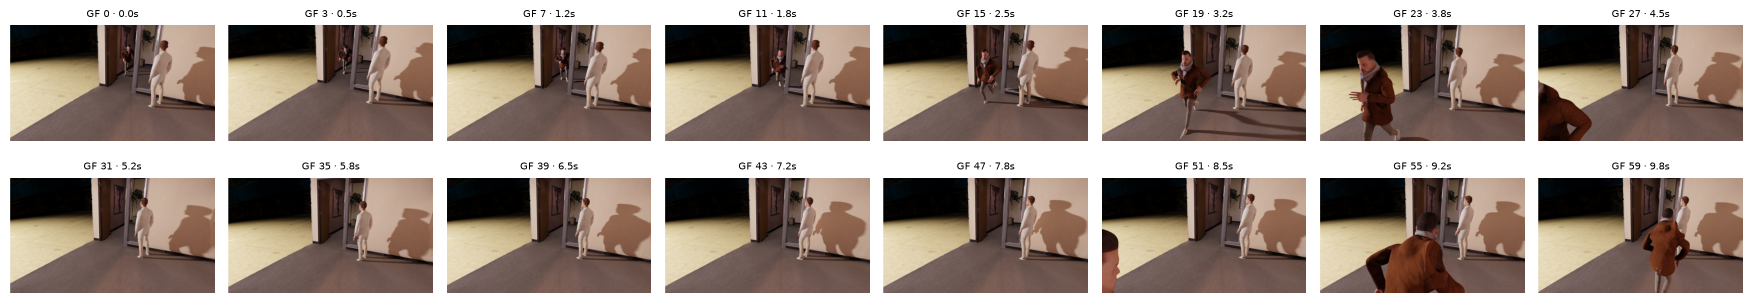

(the ground-truth answer stays hidden until step 8)


In [15]:
entry, clip = sol.entry, sol.scene.clip if sol.scene else json.loads((OUT / "clips" / sol.entry["clip_slug"] / "clip.json").read_text())
display(Markdown(f"**Question** ({entry['task']}, {entry['dataset']}): {entry['question']}"))
display(Markdown("\n".join(f"- **{k}**: {v}" for k, v in sorted(entry["options"].items()))))
rate = f"{clip['fps_gf']:g} fps ({clip['fps_status']})" if clip.get("fps_gf") else "unverified"
print(f"clip {clip['video_key']}: {clip['gf']['length']} generator frames, {rate}, "
      f"{clip['source_hw'][1]}x{clip['source_hw'][0]}{' (portrait)' if clip['portrait'] else ''}; "
      f"the benchmark's question generator saw the 16 frames below")
viz.contact_sheet(OUT, clip, title=None)
plt.show()
print("(the ground-truth answer stays hidden until step 8)")


## Step 1 — decompose: which sub-problems make up this question?

S1 reads the question and its options and produces a *Query Program*: the entities involved, the window, the measurements to make, and the claim each option makes. Templated questions are read by rules; the rest by Qwen, one small validated slot at a time. The decision path lists the D0–D7 choices that led here.

program source: rules   kind: pair_relation   route: measure   answer form: trend


**Entities (WHO)**

| id | kind | phrase | count | role | full expression |
|---|---|---|---|---|---|
| g1 | group | person | 2 | pair |  |

**Window (WHEN)**: `whole`

**Measurements (WHAT · FRAME · REDUCE)**

...

**What each option claims (OPTIONS)**

| option | text | claim |
|---|---|---|
| A | They get closer, then farther | {'trend': 'closer_then_farther'} |
| B | They get farther apart | {'trend': 'farther'} |
| C | They stay about the same distance | {'trend': 'constant'} |
| D | They get closer, then stop | {'trend': 'closer_then_constant'} |


versus the hand-written reference program: identical


### The decision path (D0–D7)

| node | asks | decided |
|---|---|---|
| D0 option form | how do the options encode the answer? | trend |
| D1 route | does geometry, time or visibility decide it? | yes -> measure |
| D2 who | which entities does the question involve? | g1=group('person') |
| D3 when | which part of the clip? | whole |
| D4 what + frame | which signal, in which reference frame? | range |
| D5 reduce | how is the signal reduced to an answer? | m1: trend |
| D6 options | what claim does each option make? | 4/4 options read into claims |
| D7 decide | clear margin and every claim checkable? | leaf B: kind 'pair_relation' is not trusted for a deterministic answer yet |
| D7 gate (this kind) | how sure must the measurement be to answer alone; who answers otherwise? | never alone for this kind (the measurement did not beat the model on dev); otherwise Qwen from the frames only |

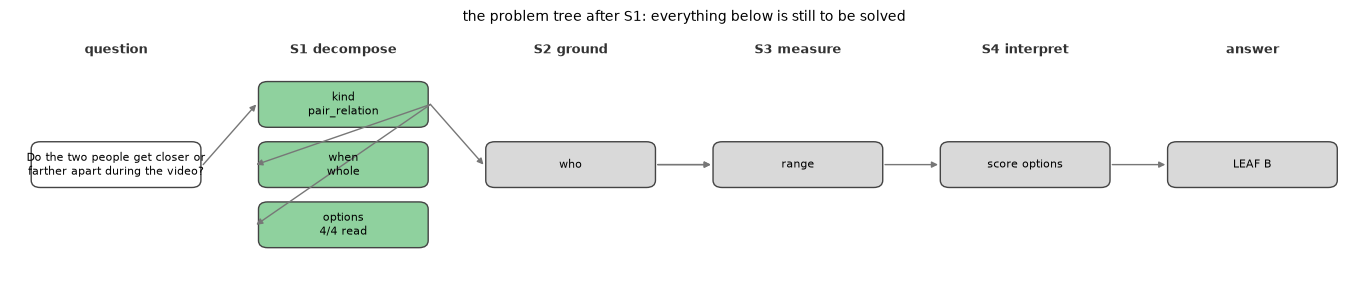

In [16]:
p = sol.program
print(f"program source: {p.source}   kind: {p.kind}   route: {p.route}   answer form: {p.answer_form}")
rows = [{"id": e.id, "kind": e.kind, "phrase": e.phrase, "count": e.count, "role": e.role,
         "full expression": e.note} for e in p.entities]
display(Markdown("**Entities (WHO)**")); display(viz.md_table(rows))
if p.events:
    display(Markdown("**Events**")); display(viz.md_table([vars(e) for e in p.events]))
w = p.window
display(Markdown(f"**Window (WHEN)**: `{w.kind}`" + (f" phase=`{w.phase}`" if w.phase else "") +
                 (f" t0={w.t0}s" if w.t0 is not None else "") + (f" t1={w.t1}s" if w.t1 is not None else "")))
display(Markdown("**Measurements (WHAT · FRAME · REDUCE)**"))
display(viz.md_table([{"id": m.id, "signal": m.signal, "of": ", ".join(m.of), "reduce": m.reduce,
                       "frame": m.frame, "metric": m.metric} for m in p.measurements]))
display(Markdown("**What each option claims (OPTIONS)**"))
display(viz.md_table([{"option": o.letter, "text": o.text, "claim": o.atoms} for o in p.options]))
if p.open_slots:
    print("open slots (filled by Qwen from the frames):", p.open_slots)
if p.duplicates:
    print("duplicate options (the earlier letter is the answer):", p.duplicates)

ref_path = OUT / "programs" / f"{qid}.reference.json"
if ref_path.exists() and PROGRAM_SOURCE != "reference":
    ref = P.QueryProgram.from_dict(json.loads(ref_path.read_text()))
    diff = P.diff_programs(p, ref)
    print("\nversus the hand-written reference program:", "identical" if not diff else "")
    for line in diff:
        print("  -", line)

display(Markdown("### The decision path (D0–D7)"))
display(viz.md_table(pipeline.decision_path(sol), ["node", "asks", "decided"], max_width=110))
tree = viz.build_tree(sol)
viz.draw_tree(tree, upto="S1", title="the problem tree after S1: everything below is still to be solved")
plt.show()


## Step 2 — when: which frames does the question mean?

Seconds are converted to frames with the source dataset's own frame rate, and the window is drawn on the clip. The blue dots are the 16 frames the benchmark's question generator saw.

window -> whole clip
time axis: 16 frames of the scene, 9.8 s


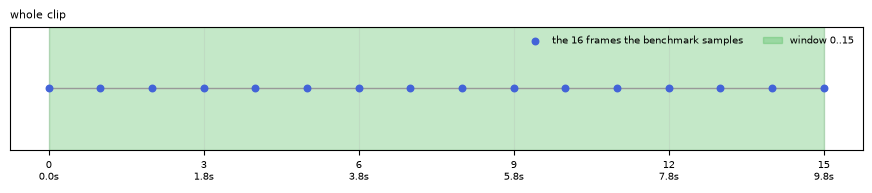

In [17]:
if sol.scene is None:
    print("no measurement is needed for this question, so there is no time axis to resolve")
else:
    win = None
    note = ""
    try:
        lo, hi, note = scene4d.resolve_window(sol.scene, p.window)
        win = (lo, hi)
    except scene4d.WindowUnresolved as error:
        note = f"window unresolved: {error}"
    print("window ->", note)
    print(f"time axis: {sol.scene.length} frames of the scene, "
          f"{'%.1f s' % sol.scene.duration_s if sol.scene.duration_s else 'no established frame rate'}")
    viz.timeline(sol.scene, sol.scene.clip, win, note)
    plt.show()


## Step 3 — who: ground every entity

SAM3 finds every instance of each phrase on every frame. A per-role policy then chooses: the best-tracked instance for one entity, the top *k* (after joining fragments of one track) for a group, all of them for a category, the most salient for the implicit main subject.

#### `g1` · group · SAM3 prompt **'person'**

| instance | frames present | mean score | mean area | centrality | rank score | used as |
|---|---|---|---|---|---|---|
| 0 | 16 | 0.953 | 0.0284 | 0.706 | 0.953 | g1[0] |
| 1 | 10 | 0.945 | 0.0316 | 0.717 | 0.591 | g1[1] |
| 2 | 3 | 0.953 | 0.104 | 0.604 | 0.179 |  |

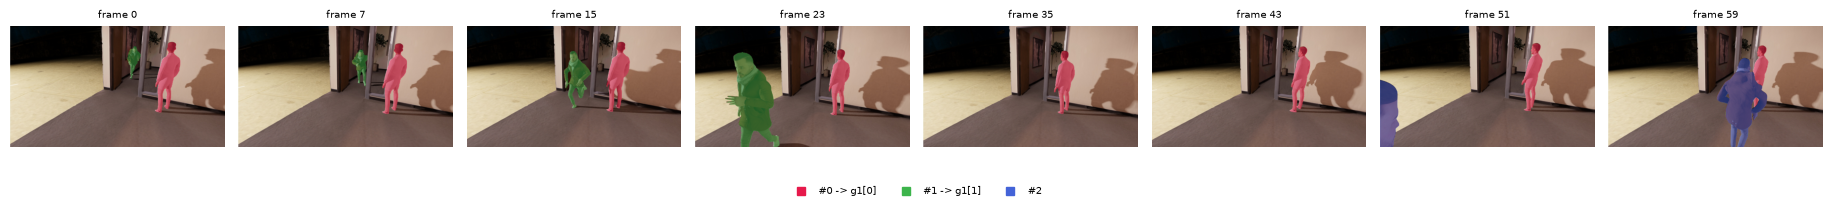

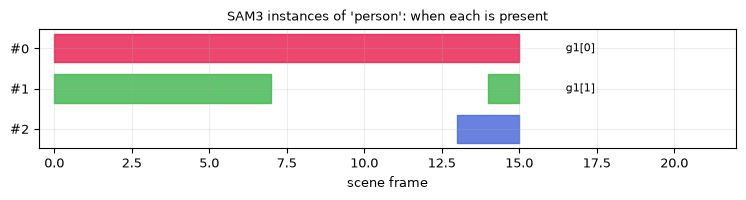

In [18]:
if sol.scene is None:
    print("nothing to ground")
elif not any(e.kind != "camera" for e in p.entities):
    print("the only entity is the camera: no segmentation is needed (it is measured from Point4D's poses)")
for e in p.entities:
    if e.kind == "camera":
        continue
    g = sol.groundings.get(e.phrase)
    display(Markdown(f"#### `{e.id}` · {e.kind} · SAM3 prompt **{e.phrase!r}**"
                     + (f"  (full expression: *{e.note}*)" if e.note else "")))
    if g is None or g.count == 0:
        print("  SAM3 found no instance of this phrase; the measurements that need it are unavailable")
        continue
    policy = "salient" if e.kind == "main_subject" else "best"
    ranked = scene4d.rank_instances(sol.scene, g, policy)
    chosen = {}
    for tr in sol.tracks.get(e.id, []):
        for k in tr.instances:
            chosen[k] = tr.id
    display(viz.md_table([{"instance": r["k"], "frames present": r["frames"], "mean score": r["score"],
                           "mean area": r["area"], "centrality": r["centrality"],
                           "rank score": r["rank_score"], "used as": chosen.get(r["k"], "")} for r in ranked]))
    if sol.tracks.get(e.id):
        for tr in sol.tracks[e.id]:
            for note in tr.notes:
                print("  note:", note)
    viz.mask_strip(OUT, sol.scene, g, chosen)
    plt.show()
    viz.lifespans(g, sol.scene, chosen)
    plt.show()


## Step 4 — where in 3D: lift the masks through the depth clouds

One Point4D pass over the whole clip gives every frame's camera pose, focal length and depth. An entity's position on a frame is the geometric median of its mask's interior cells in that frame's depth cloud, all in one world frame (the first camera).

**Interior-only rule (also used by AgentV5):** erode the mask by one depth-grid cell; never fall back to boundary cells when too few interior cells survive. Those frames retain 2D visibility evidence but have no 3D position. Motion measurements must use the smoothed trajectory; raw positions are retained for noise diagnostics. AgentV5 additionally smooths each observed span separately and returns chronological numeric tables for the model to interpret, without deterministic option scoring.

Point4D scene pass: 16 frames · world = the first camera (+X right, +Y down, +Z forward) · focal 290 -> 289 px · scene scale 1.641 units
gravity: plane (inlier fraction 0.43), up = [ 0.033 -0.928 -0.371]
metric scale (DA3-Nested): 1 unit = 1.10 m, spread (IQR/median) 0.02


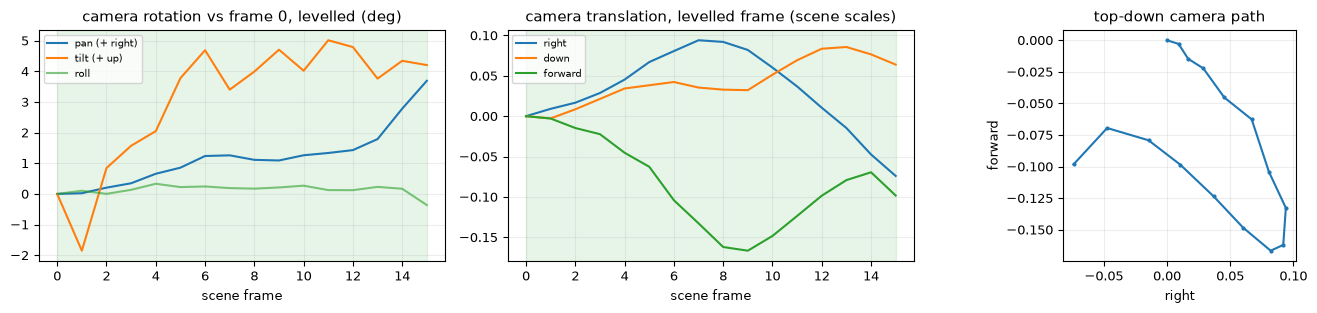

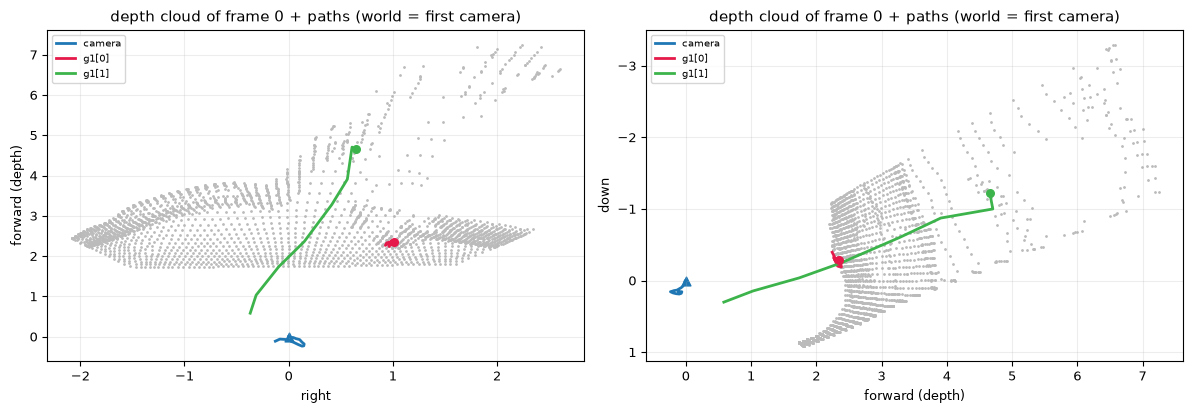

g1[0]    'person': present on 16/16 frames, 16 with enough interior mask cells, position noise 0.0000 units
g1[1]    'person': present on 10/16 frames, 8 with enough interior mask cells, position noise 0.0000 units


In [19]:
if sol.scene is None:
    print("no 3D is needed")
else:
    sc = sol.scene
    print(f"Point4D scene pass: {sc.length} frames · world = the first camera (+X right, +Y down, +Z forward) · "
          f"focal {sc.K[0,0,0]:.0f} -> {sc.K[-1,0,0]:.0f} px · scene scale {sc.scale:.3f} units")
    print(f"gravity: {sc.up_source} (inlier fraction {sc.up_fraction:.2f}), up = {sc.up}")
    if sc.metres_per_unit:
        print(f"metric scale (DA3-Nested): 1 unit = {sc.metres_per_unit:.2f} m, spread (IQR/median) {sc.metric_iqr:.2f}")
    viz.camera_plot(sc, measure.camera_state(sc), next(iter(sol.results.values()), None))
    plt.show()
    if sol.tracks:
        viz.scene_3d(sc, sol.tracks, frame=0)
        plt.show()
        for eid, lst in sol.tracks.items():
            for tr in lst:
                print(f"{tr.id:8s} {tr.phrase!r}: present on {int(tr.present.sum())}/{sc.length} frames, "
                      f"{int(tr.confident.sum())} with enough interior mask cells, position noise {tr.noise:.4f} units")


## Step 4b — no points near the segmentation boundary (AgentV5 rule)

At a silhouette the depth map blends foreground and background, and a SAM3 mask edge does not line up exactly with the depth model's edge. AgentV5 (`d4rt_agent/agent_v5/sampling.py`, branch `feat/agent-v5`) keeps a depth cell only if (1) it is at least `max(4 px, 25% of the mask's inscribed radius, one cell)` inside the mask, and (2) its depth does not jump by more than 10% to any neighbouring cell (the depth map's own silhouette). Too few cells left: the margin is halved down to one cell, never removed; a mask too thin for an interior gives no 3D position on that frame. Below: one frame of the selected entity under the research rule and the v5 rule, and the position noise of the whole track under each.

In [ ]:
# The boundary rule as AgentV5 (branch feat/agent-v5) applies it: d4rt_agent/agent_v5/sampling.py
try:
    from d4rt_agent.agent_v5.sampling import interior_cells
except ImportError as error:
    interior_cells = None
    print("needs the feat/agent-v5 code (d4rt_agent/agent_v5/sampling.py) on the path:", error)
from scipy.ndimage import binary_erosion

def _mask_of(sc, g, tr, pos):
    mask = np.zeros(g.masks.shape[2:], dtype=bool)
    for k in tr.instances:
        mask |= g.masks[k, int(sc.gf_index[pos])]
    return mask

def _median_of(sc, pos, cells):
    from d4rt_agent.sam_orientany_d4rt_test.traj3d_geometry import geometric_median
    pts = sc.points[pos][cells]
    pts = pts[np.isfinite(pts).all(1)]
    return geometric_median(pts) if len(pts) >= 3 else np.full(3, np.nan)

tracked = [(eid, tr) for eid, lst in sol.tracks.items() for tr in lst]
if sol.scene is None or not tracked or interior_cells is None:
    print("no entity to lift for this question")
else:
    sc = sol.scene
    eid, tr = tracked[0]
    g = sol.groundings[next(e.phrase for e in p.entities if e.id == eid.split("[")[0])]
    present = np.flatnonzero(tr.present)
    pos = int(present[len(present) // 2])
    mask = _mask_of(sc, g, tr, pos)
    inside = scene4d._cell_coverage(mask, sc.points.shape[1:3]) >= 0.5
    old = binary_erosion(inside, structure=np.ones((3, 3), dtype=bool))
    new = interior_cells(mask, sc.points[pos], sc.cam_R[pos], sc.cam_t[pos])
    depth = ((sc.points[pos] - sc.cam_t[pos]) @ sc.cam_R[pos])[..., 2]
    fig, ax = plt.subplots(1, 4, figsize=(15, 3.4))
    ax[0].imshow(mask, cmap="Greys"); ax[0].set_title(f"{tr.id} mask, scene frame {pos}")
    ax[1].imshow(np.where(inside, depth, np.nan)); ax[1].set_title("depth of the mask's cells")
    ax[2].imshow(old, cmap="Blues"); ax[2].set_title(f"research rule: 1-cell erosion ({int(old.sum())})")
    shown = new.cells if new.cells is not None else np.zeros_like(old)
    ax[3].imshow(shown, cmap="Greens")
    ax[3].set_title(f"v5: margin {new.margin_px:.1f} px + depth edges ({int(shown.sum())}; "
                    f"{new.depth_edge_cells} on a depth edge)")
    for a in ax: a.set_xticks([]); a.set_yticks([])
    plt.show()
    for name, cells in (("1-cell erosion", old), ("v5 interior", shown)):
        d = depth[cells & np.isfinite(depth)]
        if len(d):
            print(f"{name:15s}: {int(cells.sum()):4d} cells, depth median {np.median(d):.3f}, "
                  f"spread (IQR/median) {np.subtract(*np.percentile(d, [75, 25])) / np.median(d):.3f}")
    # the whole track both ways: a rule that keeps background bleed shows it as position noise
    paths = {"1-cell erosion": [], "v5 interior": []}
    for q in present:
        m = _mask_of(sc, g, tr, int(q))
        cov = scene4d._cell_coverage(m, sc.points.shape[1:3]) >= 0.5
        paths["1-cell erosion"].append(_median_of(sc, int(q), binary_erosion(cov, structure=np.ones((3, 3), bool))))
        cells = interior_cells(m, sc.points[int(q)], sc.cam_R[int(q)], sc.cam_t[int(q)]).cells
        paths["v5 interior"].append(_median_of(sc, int(q), cells) if cells is not None else np.full(3, np.nan))
    from d4rt_agent.sam_orientany_d4rt_test.traj3d_geometry import smooth_trajectory
    for name, xyz in paths.items():
        xyz = np.asarray(xyz)
        resid = np.linalg.norm(xyz - smooth_trajectory(xyz, window=scene4d.smoothing_window(sc, len(xyz)), polyorder=2), axis=1)
        resid = resid[np.isfinite(resid)]
        print(f"{name:15s}: 3D position on {int(np.isfinite(xyz).all(1).sum())}/{len(xyz)} frames, "
              f"position noise (MAD of the residual) {1.4826 * np.median(np.abs(resid - np.median(resid))):.4f} units")


## Step 4c — which trajectory is read: raw or smoothed

Every measurement must read the smoothed path; the raw one is for noise floors only. Entity paths were already read smoothed here; AgentV5 additionally smooths the camera's rotation angles before reading a pan or tilt off them (AgentV4 read a 5-frame running mean of a re-loaded raw path, never its own Savitzky-Golay track).

In [ ]:
# Which series the measurements read: the smoothed one (draft: "they were not using the smoothened trajectory")
if sol.scene is None:
    print("no 3D is needed")
else:
    sc = sol.scene
    t = sc.t_s if sc.t_s is not None else np.arange(sc.length)
    cam = measure.camera_state(sc)
    from d4rt_agent.sam_orientany_d4rt_test.traj3d_geometry import smooth_trajectory
    pan_raw = np.degrees(np.unwrap(np.radians(cam["pan"])))
    pan_v5 = smooth_trajectory(np.stack([pan_raw] * 3, 1), window=scene4d.smoothing_window(sc, sc.length), polyorder=2)[:, 0]
    tracked = [tr for lst in sol.tracks.values() for tr in lst]
    fig, ax = plt.subplots(1, 1 + len(tracked[:2]), figsize=(5 * (1 + len(tracked[:2])), 3.2), squeeze=False)
    ax = ax[0]
    ax[0].plot(t, pan_raw, ".", ms=3, label="pan, raw (research pipeline reads this)")
    ax[0].plot(t, pan_v5, "-", label="pan, smoothed (AgentV5 reads this)")
    ax[0].set_title("camera pan (deg)"); ax[0].legend(fontsize=7)
    for a, tr in zip(ax[1:], tracked[:2]):
        for i, name in ((0, "x right"), (2, "z forward")):
            a.plot(t, tr.xyz[:, i], ".", ms=3, label=f"{name}, raw")
            a.plot(t, tr.smooth[:, i], "-", label=f"{name}, smoothed (read by every measurement)")
        a.set_title(f"{tr.id} position (units)"); a.legend(fontsize=7)
    plt.show()
    print("Entity measurements (range, displacement, speed, onsets) read track.smooth in both pipelines;")
    print("AgentV5 also smooths the camera's pan/tilt/roll before reading a motion off them, and keeps the raw")
    print("series only for noise floors and the shake residual (d4rt_agent/agent_v5/measure.py: camera_state).")


## Step 5 — measure: each sub-problem's signal

Every measurement is drawn with its window and noise band.

#### `m1` · range → trend

  whole clip · confidence high


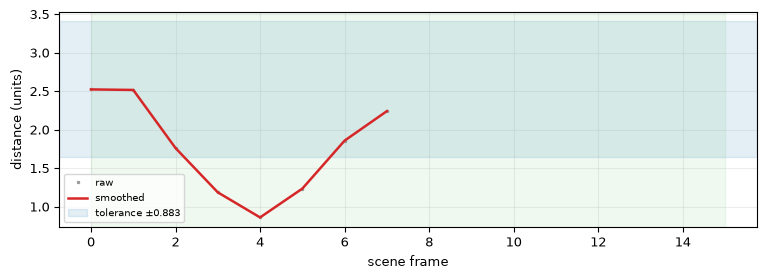

In [20]:
for m in p.measurements:
    r = sol.results.get(m.id)
    display(Markdown(f"#### `{m.id}` · {m.signal} → {m.reduce}" + (f" · frame `{m.frame}`" if m.frame else "")))
    if r is None or not r.available:
        print("  NOT MEASURED:", None if r is None else r.reason)
        continue
    print(f"  {r.window_note or 'whole clip'} · confidence {r.confidence}")
    for n in r.notes:
        print("  note:", n)
    if m.signal == "camera_motion":
        viz.camera_plot(sol.scene, measure.camera_state(sol.scene), r); plt.show()
        print("  strength of each motion family (1.0 = at its floor):", r.value["strength"])
    elif m.signal == "camera_jitter":
        fig, ax = plt.subplots(figsize=(9, 2.6))
        ax.plot(r.series["frames"], r.series["pan_residual"], label="pan residual (deg)")
        ax.plot(r.series["frames"], r.series["tilt_residual"], label="tilt residual (deg)")
        ax.set(title="what is left after removing the smooth camera path", xlabel="scene frame"); ax.legend(); plt.show()
    elif m.signal in ("range", "region_distance"):
        if m.reduce == "value_at":
            viz.series_plot(r, "distance (units)", marks={"asked": r.value["frame"]}); plt.show()
        else:
            viz.series_plot(r, "distance (units)"); plt.show()
    elif m.signal == "displacement":
        fr = r.value["frames"]
        rows = []
        for frame, comp in fr.items():
            for toward in (False, True):
                conv = {"frame": frame, "z_toward_camera": toward}
                words = interpret.direction_words(r.value, conv)["words"]
                rows.append({"frame": frame, "'forward' means": "toward the camera" if toward else "away from it",
                             "x": words["x"], "y": words["y"], "z": words["z"]})
        display(Markdown("The same displacement in every reference frame. Which frame and which sign of *forward* the "
                         "benchmark's generator used is a convention, so all are shown; `interpret.DIRECTION_CONVENTION` "
                         "holds the calibrated choice."))
        display(viz.md_table(rows))
        print("  the choice in force:", interpret.DIRECTION_CONVENTION)
    elif m.signal == "speed_metric":
        t, pos, picks = r.series["t"], r.series["pos"], r.series["picks"]
        fig, ax = plt.subplots(1, 2, figsize=(10, 2.8))
        ax[0].plot(pos[:, 0], pos[:, 2], ".-", color="#1f77b4", alpha=0.6)
        ax[0].plot(pos[picks, 0], pos[picks, 2], "o", color="#d62728", ms=4, label="half-second steps")
        ax[0].set(title="the subject's path from above (world, units)", xlabel="right", ylabel="forward"); ax[0].invert_yaxis(); ax[0].legend()
        step = np.linalg.norm(np.diff(pos[picks], axis=0), axis=1) / np.diff(t[picks])
        ax[1].step(t[picks][1:], step, where="post", color="#2c3e50")
        ax[1].axhline(r.value["net_units_per_s"], ls="--", color="#3cb44b", label="start-to-end")
        ax[1].axhline(r.value["path_units_per_s"], ls=":", color="#d35400", label="distance travelled")
        ax[1].set(title="speed per half second (units / s)", xlabel="seconds"); ax[1].legend(); plt.show()
        if "mps" in r.value:
            print(f"  x {r.value['metres_per_unit']:.2f} m per unit (scale spread {r.value['scale_iqr_over_median']:.2f}) -> {r.value['mps']:.2f} m/s "
                  f"[start-to-end {r.value['net_mps']:.2f}, travelled {r.value['path_mps']:.2f}]; the mode calibration chose: {r.value['mode']}")
    elif m.signal == "camera_displacement":
        fig, ax = plt.subplots(figsize=(9, 2.6))
        tr = r.series["trans"] - r.series["trans"][r.window[0]]
        for i, name in enumerate(("right", "down", "forward")):
            ax.plot(r.series["frames"], tr[:, i], label=name)
        ax.axvspan(*r.window, color="#f5b041", alpha=0.25, label="the window asked about")
        ax.set(title="camera position relative to its start, gravity-levelled (units)", xlabel="scene frame"); ax.legend(); plt.show()
        words = interpret.direction_words(r.value)
        print("  the camera moved:", {k: v for k, v in words["words"].items() if v} or "too little to name")
    elif m.signal == "instances":
        print("  instances by minimum lifespan:", r.value["by_min_lifespan"], "· stable:", r.value["stable"])
        for i, (a, b, n) in enumerate(r.value["lifespans"]):
            print(f"  tracklet {i}: frames {a}..{b} ({n} present)")
    elif m.signal == "onset":
        fig, ax = plt.subplots(figsize=(9, 2.4))
        s = r.series.get("signal")
        if s is not None:
            ax.plot(s, color="#1f77b4")
        if r.value["onset"] is not None:
            ax.axvline(r.value["onset"], color="#d62728", ls="--", label=f"onset: frame {r.value['onset']}")
        ax.set(title=f"{r.value['predicate']} of {r.value['actor']}", xlabel="scene frame"); ax.legend(); plt.show()
    elif m.signal == "order":
        print("  onsets:", r.value["onsets"], "-> first:", r.value["first"])
    elif m.signal == "focal":
        fig, ax = plt.subplots(figsize=(9, 2.6))
        ax.plot(r.series["frames"], r.series["focal"] / r.series["focal"][0], label="focal length / first")
        ax.axhline(1 + measure.TUNING["zoom_rel_tol"], ls=":", color="#444"); ax.axhline(1 / (1 + measure.TUNING["zoom_rel_tol"]), ls=":", color="#444")
        ax.set(title=f"Point4D's focal length per frame -> zoom: {r.value['zoom']}", xlabel="scene frame"); ax.legend(); plt.show()
        print(f"  the camera also moved {r.value['forward_over_scale']:+.2f} scene scales forward (a dolly makes a subject grow without any zoom)")
    elif m.signal == "camera_speed":
        fig, ax = plt.subplots(figsize=(9, 2.6))
        ax.plot(r.series["frames"], r.series["energy"], color="#1f77b4")
        ax.axhline(1.0, ls=":", color="#444", label="moving above this (1 = the floor)")
        for k, part in enumerate(np.array_split(np.arange(len(r.series["energy"])), 3)):
            ax.axvspan(r.series["frames"][part[0]], r.series["frames"][part[-1]], color=["#dfe", "#ffe", "#fde"][k], alpha=0.5)
        ax.set(title=f"camera speed profile (translation + rotation, in floors) -> {r.value['rhythm']}", xlabel="scene frame"); ax.legend(); plt.show()
        print("  mean energy per third of the clip:", np.round(r.value["thirds"], 2), "· coefficient of variation", round(r.value["cv"], 2))
    elif m.signal == "covisibility":
        print(f"  {r.value['shared_fraction']:.0%} of the first view's surface is seen again, consistently, from the last camera "
              f"(in view {r.value['in_view_fraction']:.0%}); camera turned {r.value['pan_deg']:+.1f} deg and moved {r.value['translation_over_scale']:.2f} scales")
    elif m.signal == "area":
        fig, ax = plt.subplots(figsize=(9, 2.6))
        ax.plot(r.series["frames"], 100 * r.series["area"], ".-", color="#8e44ad")
        ax.set(title=f"mask area (% of image) -> {r.value['size']} (end/start = {r.value['area_ratio_end']:.2f})", xlabel="scene frame"); plt.show()
    elif m.signal == "presence":
        fig, ax = plt.subplots(figsize=(9, 1.8))
        ax.fill_between(r.series["frames"], 0, r.series["present"], step="mid", color="#3cb44b", alpha=0.6)
        if r.window: ax.axvspan(*r.window, color="#f5b041", alpha=0.3, label="the window asked about")
        ax.set(title=f"subject in the frame? -> {r.value['visible']}", xlabel="scene frame", yticks=[]); ax.legend(); plt.show()
        print("  present in the window:", f"{r.value['present_fraction']:.0%}", "· touching the border:", r.value["border_fraction"], "· area vs its usual:", r.value["relative_area"])
    elif m.signal == "elevation":
        fig, ax = plt.subplots(figsize=(9, 2.6))
        ax.plot(r.series["frames"], r.series["elevation"], color="#d35400")
        ax.axhspan(-measure.TUNING["elev_eye_deg"], measure.TUNING["elev_eye_deg"], color="#3cb44b", alpha=0.15, label="eye level")
        ax.set(title=f"camera elevation above the subject (deg, vs gravity) -> {r.value['angle']}", xlabel="scene frame"); ax.legend(); plt.show()
    elif m.signal == "speed":
        fig, ax = plt.subplots(figsize=(9, 2.6))
        ax.plot(r.series["frames"], r.series["speed"], color="#2c3e50")
        ax.axhline(r.value["floor_per_s"], ls=":", color="#444", label="moving above this")
        ax.fill_between(r.series["frames"], 0, r.series["speed"], where=r.series["moving"], color="#3cb44b", alpha=0.3)
        ax.set(title=f"subject speed (scene scales / s) -> {r.value['motion']} ({r.value['runs']} run(s))", xlabel="scene frame"); ax.legend(); plt.show()


## Step 6 — reduce: signals become typed values

Value, noise floor, confidence.

| measurement | signal | value | floor | confidence |
|---|---|---|---|---|
| m1 | range | {'trend': 'closer_then_farther', 'net_units': -0.28171, 'start_units': 2.5238, 'end_units': 2.24209, 'tolerance_units': 0.88333, 'ratio_end… | {'tolerance_units': 0.88333, 'noise_log': 0.0} | high |

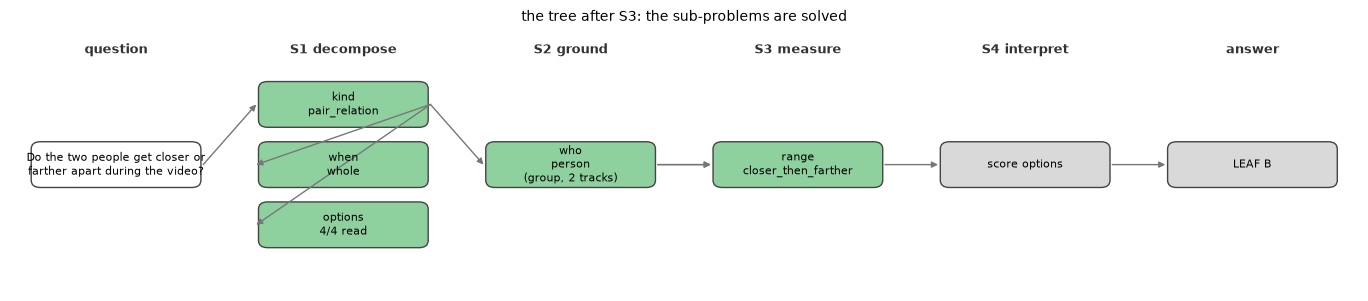

In [21]:
display(viz.md_table([{"measurement": m.id, "signal": m.signal,
                       "value": (sol.results[m.id].to_dict()["value"] if m.id in sol.results and sol.results[m.id].available else "UNAVAILABLE"),
                       "floor": (sol.results[m.id].to_dict()["floor"] if m.id in sol.results else None),
                       "confidence": (sol.results[m.id].confidence if m.id in sol.results else None)}
                      for m in p.measurements], max_width=140))
viz.draw_tree(tree, upto="S3", title="the tree after S3: the sub-problems are solved")
plt.show()


## Step 7 — interpret: which option does the measurement support?

Interpreting a measurement matters as much as making it. Each option's claim is checked; leaf A answers only when the best option is clearly supported, clearly ahead of the rest, and every claim it makes could be checked.

Each option is a claim. It is checked against the measurement, and a claim that cannot be checked scores nothing rather than being guessed.

| option | score | verdict | why |
|---|---|---|---|
| A | 1 | match | measured closer_then_farther |
| B | 0 | mismatch | measured closer_then_farther, option says farther |
| C | 0 | mismatch | measured closer_then_farther, not constant |
| D | 0 | mismatch | measured closer_then_farther |

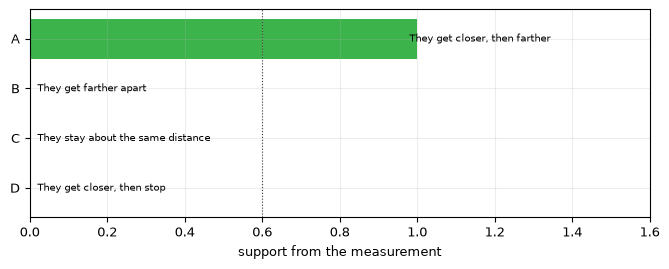

decision: leaf B  ·  margin 1.00  ·  kind 'pair_relation' is not trusted for a deterministic answer yet
the gate for 'pair_relation': 9.0 support, 9.0 margin (posterior margin 9.0 with the kind's base rate); when it does not answer alone: Qwen from the frames only


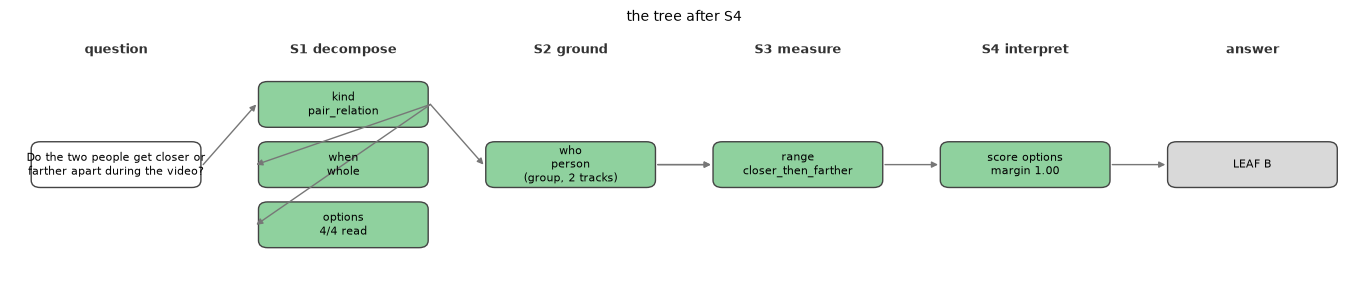

In [22]:
d = sol.decision
if not d.scores:
    print("no option is scored: this question is decided by what is happening, not by a measurement (leaf C)")
else:
    display(Markdown("Each option is a claim. It is checked against the measurement, and a claim that cannot be checked "
                     "scores nothing rather than being guessed."))
    display(viz.md_table([{"option": s.letter, "score": s.score, "verdict": s.verdict, "why": s.detail} for s in d.scores],
                         max_width=120))
    viz.option_bars(d)
    plt.show()
print(f"decision: leaf {d.leaf}  ·  margin {d.margin:.2f}  ·  {d.reason}")
print(f"the gate for {p.kind!r}: {interpret.gate(p.kind)['min_score']} support, {interpret.gate(p.kind)['min_margin']} margin"
      + (f" (posterior margin {interpret.gate(p.kind)['fused_margin']} with the kind's base rate)" if p.kind in interpret.FUSE_KINDS else "")
      + "; when it does not answer alone: " + {"evidence": "Qwen with the frames and the measured evidence", "frames": "Qwen from the frames only",
                                               "fused": "Qwen's option probabilities x the measurement's support (soft fusion)"}[pipeline.FALLBACK_BY_KIND.get(p.kind, "evidence")])
viz.draw_tree(tree, upto="S4", title="the tree after S4")
plt.show()


## Step 8 — assemble the answer

The ground truth is revealed here, next to the baselines.

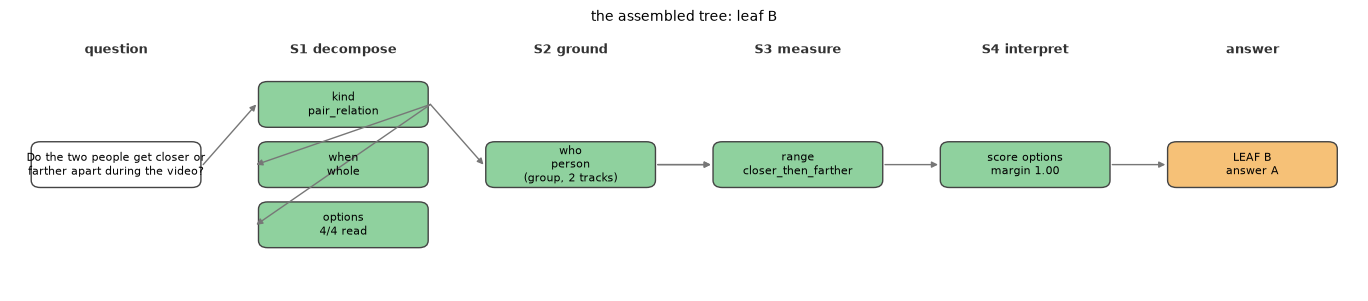

| who | answer | via | correct |
|---|---|---|---|
| this pipeline | A | frames | False |
| Qwen3-VL-8B from the frames alone | A | no tools | False |
| Qwen3-VL-8B with the evidence |  | leaf B |  |
| ground truth | B |  |  |

correct option B: They get farther apart


**What leaf B showed Qwen next to the frames:**

A 3D reconstruction of the video was measured. Its findings (units are model-relative unless metres are stated):
- [high confidence] the distance between person #1 and person #2 first shrinks, then grows: from 2.524 to 2.242 model units; changes under 0.883 are not counted.
Comparison of each option with those findings:
- A: match -- measured closer_then_farther
- B: mismatch -- measured closer_then_farther, option says farther
- C: mismatch -- measured closer_then_farther, not constant
- D: mismatch -- measured closer_then_farther
The reconstruction can be wrong (segmentation or depth failures, thresholds); where it disagrees with the frames, trust what you can see.


In [23]:
gt = sol.entry["answer"]
viz.draw_tree(tree, title=f"the assembled tree: leaf {sol.decision.leaf}")
plt.show()
rows = [{"who": "this pipeline", "answer": sol.final, "via": sol.final_source, "correct": sol.correct},
        {"who": "Qwen3-VL-8B from the frames alone", "answer": sol.frames_only, "via": "no tools",
         "correct": None if sol.frames_only is None else sol.frames_only == gt},
        {"who": "Qwen3-VL-8B with the evidence", "answer": sol.evidence_answer, "via": "leaf B",
         "correct": None if sol.evidence_answer is None else sol.evidence_answer == gt},
        {"who": "ground truth", "answer": gt, "via": "", "correct": None}]
display(viz.md_table(rows))
print(f"correct option {gt}: {sol.entry['options'][gt]}")
if sol.decision.leaf == "B":
    display(Markdown("**What leaf B showed Qwen next to the frames:**"))
    print(interpret.evidence_text(sol.program, sol.results, sol.decision))


## What to distrust

1. **A wrong entity.** SAM3 grounds a phrase, not an intention: "person" matches everyone, and the
   implicit *main subject* is a guess from the frames. Nothing downstream can detect it, so step 3
   shows every candidate instance.
2. **Depth of small or thin things.** A position is the median of the eroded mask's cells in a
   stride-4 depth cloud. A few cells, or a mask on the silhouette, gives a noisy point; `confident`
   marks the frames that stand on enough interior cells.
3. **Point4D units.** Distances are model-relative; metres use one median ratio to DA3-Nested with
   its spread reported. A metric answer is only as good as that ratio.
4. **The generator's conventions.** Which reference frame "moves right and forward" is read in,
   how many degrees a "noticeable pan" is, what "stable" means: none of these is physics. They are
   named, and calibrated on dev clips, not derived.
5. **Frame rate.** Handheld shake is aliased at 6 fps, so a residual understates it; confidence is
   lowered where that applies.
6. **Absent is not unknown.** An entity that leaves the frame has no position; a measurement over
   the frames where two entities are both visible may miss the start or the end of the story.
7. **Leaf A is a claim of certainty.** It may answer alone only for a kind whose gate beat the language
   model on dev clips (`interpret.TRUSTED_KINDS`, `interpret.DECISION_BY_KIND`); for the other kinds
   the measurement is evidence for Qwen, not a verdict.
8. **The forward/backward words.** Left/right is read reliably from the first camera's axes; "forward"
   and "backward" are close to a coin flip against the benchmark's answers, and the pipeline weights
   the axes accordingly (`interpret.DECISION['dir_w_*']`) instead of letting one unreliable axis
   decide an option.


## Batch view

The same flow over every question of the catalog. Not a benchmark number: a check that the branches hold together, and where each falls back.

In [24]:
# the whole small catalog; for the dev catalog an even sample of it (every kind, in catalog order)
qids = list(ctx.catalog)
if len(qids) > 200:
    qids = qids[:: max(1, len(qids) // 200)]
sols = [pipeline.solve(ctx, q, source=PROGRAM_SOURCE, temporal=TEMPORAL) for q in qids]
rows = pipeline.summary_rows(sols)
display(viz.md_table(rows[:60], ["qid", "kind", "leaf", "margin", "measured", "final", "src", "gt", "ok", "frames_only"]))
from collections import Counter
def acc(subset, key):
    known = [s for s in subset if key(s) is not None]
    return f"{sum(key(s) for s in known)}/{len(known)}" if known else "-"
print("\naccuracy   pipeline   frames-only   (questions where the pipeline chose each leaf)")
for leaf in "ABC":
    sub = [s for s in sols if s.decision.leaf == leaf]
    if sub:
        print(f"leaf {leaf}:  {acc(sub, lambda s: s.correct):>8}   "
              f"{acc(sub, lambda s: None if s.frames_only is None else s.frames_only == s.entry['answer']):>8}      n={len(sub)}")
print(f"overall: {acc(sols, lambda s: s.correct):>8}   "
      f"{acc(sols, lambda s: None if s.frames_only is None else s.frames_only == s.entry['answer']):>8}")


| qid | kind | leaf | margin | measured | final | src | gt | ok | frames_only |
|---|---|---|---|---|---|---|---|---|---|
| cameraqa_davis_lab_coat_6b077a14_0 | camera_path | A | 0.52 | A | A | measurement | A | True | A |
| cameraqa_dynamic_replica_04ff5e_4_obj_source_l | camera_shake | A | 1 | A | A | measurement | A | True | A |
| cameraqa_dynpose_32439b6a_737d_473b_b7fb_3aead | cam_subject_range | B | 1 | D | B | frames | C | False | B |
| qa_ytvis_1b0ad425e5_b6f634ee_0 | subject_direction | B | 0.13 | C | B | frames | A | False | B |
| qa_dynamic_replica_04ff5e_4_obj_source_left_f2 | pair_relation | B | 1 | A | A | frames | B | False | A |
| qa_dynpose_32439b6a_737d_473b_b7fb_3aead1f6d0c | metric_distance | B | 0.72 | A | B | frames | A | False | B |
| qa_sav_017974_manual_818c7cc6_1 | instance_count | B | 0.7 | B | B | frames | B | True | B |
| cameraqa_sav_026989_manual_8cbd9e78_2 | event_order | B | 1 | A | A | frames | A | True | A |
| sceneqa_davis_boat_d573aaba_1 | landmark_relation | B | 0.75 | A | B | frames | C | False | B |
| qa_sav_000040_manual_b7fd5545_0 | semantic | C | 0 |  | A | frames | A | True | A |


accuracy   pipeline   frames-only   (questions where the pipeline chose each leaf)
leaf A:       2/2        2/2      n=2
leaf B:       2/7        2/7      n=7
leaf C:       1/1        1/1      n=1
overall:     5/10       5/10


## Results: what the finished pipeline scores

Every threshold was chosen on dev clips only (never on a clip that is scored below as test). `pipeline` is the whole flow — the measurement answers alone where its gate allows, Qwen with the evidence otherwise; `frames-only` is Qwen3-VL-8B with the same 16 frames and no tools; `evidence` is Qwen with the frames and the measurements on every question.

In [25]:
# What calibration changed, and what the finished pipeline scores (dev clips fit, test clips report).
d0, d1 = pipeline.DEFAULTS, pipeline.snapshot()
changed = []
for group, label in (("t", "measure.TUNING"), ("d", "interpret.DECISION"), ("s", "scene4d")):
    for k, v in d1[group].items():
        if d0[group].get(k) != v:
            changed.append({"constant": f"{label}[{k}]", "default": d0[group].get(k), "calibrated": v})
if d0["conv"] != d1["conv"]:
    changed.append({"constant": "direction convention", "default": d0["conv"], "calibrated": d1["conv"]})
display(Markdown("**Constants moved off their defaults by the dev-clip calibration**"))
display(viz.md_table(changed, max_width=90))
display(Markdown(f"frame set per kind: `{d1['temporal']}`  \nfusion with the kind's base rate: `{d1['fuse']['kinds']}`  \n"
                 f"kinds allowed to answer alone: `{d1['trusted']}`  \nfallback per kind: `{d1['fallback']}`"))
gates = OUT.parent / "decomposition_dev" / "gates.json"
if gates.exists():
    tables = json.loads(gates.read_text())["tables"]
    notes = {"dev": "the constants above were chosen here", "test": "not used to choose the measurement constants",
             "heldout": "added last; nothing fitted on it until the final policy fit"}
    for split in ("dev", "test", "heldout"):
        if split in tables:
            display(Markdown(f"**{split} clips** ({notes[split]}; the policy itself is fitted on all three, so quote the cross-validation in logs/DECOMPOSITION.md)"))
            display(viz.md_table(tables[split], max_width=40))
else:
    print("run `python -m dyn_dataset_exploration.decomposition.run_gates` to produce the per-kind results table")

census = REPO / "dyn_dataset_exploration" / "outputs" / "decomposition_census" / "census.json"
if census.exists():
    c = json.loads(census.read_text())
    route = {k.name: k.route for k in P.KINDS}
    rows = [{"kind": k, "route": route.get(k, "-"), "questions": v, "share": f"{100 * v / c['n']:.1f}%"}
            for k, v in sorted(c["counts"].items(), key=lambda kv: -kv[1])]
    display(Markdown(f"**How much of Dyn-Bench the graph reaches** ({c['n']} questions; rules read the templated ones, "
                     f"Qwen3-VL names the kind of the rest from the text alone): "
                     f"{c['measured']} ({100 * c['measured'] / c['n']:.0f}%) go to a measurement, the rest are answered from the frames."))
    display(viz.md_table(rows, max_width=40))


**Constants moved off their defaults by the dev-clip calibration**

| constant | default | calibrated |
|---|---|---|
| measure.TUNING[cam_pan_deg] | 6 | 4 |
| measure.TUNING[cam_trans_scales] | 0.12 | 0.5 |
| measure.TUNING[cam_complex_ratio] | 0.6 | 1 |
| measure.TUNING[jitter_slight_deg] | 0.25 | 0.05 |
| measure.TUNING[jitter_shaky_deg] | 0.8 | 0.25 |
| measure.TUNING[range_rel_tol] | 0.15 | 0.35 |
| measure.TUNING[pair_rel_tol] | 0.15 | 0.35 |
| measure.TUNING[axis_dominance] | 0.35 | 0.25 |
| measure.TUNING[tie_frames] | 1 | 0 |
| measure.TUNING[cam_dir_floor_scales] | 0.05 | 0.2 |
| measure.TUNING[zoom_rel_tol] | 0.1 | 0.35 |
| measure.TUNING[size_rel_tol] | 0.3 | 0.7 |
| measure.TUNING[vis_partial_area] | 0.5 | 0.3 |
| measure.TUNING[rhythm_trans_floor_per_s] | 0.02 | 0.1 |
| measure.TUNING[rhythm_burst_ratio] | 2.2 | 3.5 |
| measure.TUNING[revisit_same_frac] | 0.85 | 0.3 |
| measure.TUNING[revisit_diff_frac] | 0.35 | 0.1 |
| direction convention | {'frame': 'camera_rel', 'z_toward_camera': False} | {'frame': 'world0', 'z_toward_camera': False} |

frame set per kind: `{'camera_path': 'sampled16', 'camera_shake': 'all', 'cam_subject_range': 'sampled16', 'pair_relation': 'sampled16', 'subject_direction': 'all', 'metric_distance': 'sampled16', 'landmark_relation': 'all', 'camera_translation': 'all', 'metric_speed': 'sampled16', 'event_order': 'all', 'instance_count': 'all', 'camera_zoom': 'all', 'apparent_size': 'all', 'subject_visibility': 'sampled16', 'cam_subject_elevation': 'all', 'camera_rhythm': 'all', 'scene_revisit': 'all', 'subject_motion_profile': 'sampled16'}`  
fusion with the kind's base rate: `['camera_path', 'camera_rhythm', 'camera_translation', 'instance_count', 'pair_relation', 'subject_visibility']`  
kinds allowed to answer alone: `['apparent_size', 'cam_subject_elevation', 'camera_path', 'camera_rhythm', 'camera_shake', 'camera_translation', 'subject_direction', 'subject_visibility']`  
fallback per kind: `{'apparent_size': 'fused', 'cam_subject_elevation': 'frames', 'cam_subject_range': 'evidence', 'camera_path': 'fused', 'camera_rhythm': 'fused', 'camera_shake': 'fused', 'camera_translation': 'fused', 'camera_zoom': 'evidence', 'event_order': 'frames', 'instance_count': 'fused', 'landmark_relation': 'fused', 'metric_distance': 'fused', 'metric_speed': 'fused', 'pair_relation': 'frames', 'scene_revisit': 'evidence', 'subject_direction': 'fused', 'subject_motion_profile': 'frames', 'subject_visibility': 'evidence'}`

**dev clips** (the constants above were chosen here; the policy itself is fitted on all three, so quote the cross-validation in logs/DECOMPOSITION.md)

| kind | n | pipeline | frames-only | qwen letters | evidence | answers alone | alone acc |
|---|---|---|---|---|---|---|---|
| apparent_size | 44 | 31/44 (70%) | 24/44 (55%) | 25/44 (57%) | 31/44 (70%) | 0 | - |
| cam_subject_elevation | 39 | 26/39 (67%) | 16/39 (41%) | 18/39 (46%) | 23/39 (59%) | 0 | - |
| cam_subject_range | 135 | 84/135 (62%) | 54/135 (40%) | 67/135 (50%) | 84/135 (62%) | 0 | - |
| camera_path | 139 | 104/139 (75%) | 68/139 (49%) | 84/139 (60%) | 102/139 (73%) | 103 | 83/103 (81%) |
| camera_rhythm | 95 | 76/95 (80%) | 55/95 (58%) | 58/95 (61%) | 65/95 (68%) | 86 | 69/86 (80%) |
| camera_shake | 47 | 27/47 (57%) | 17/47 (36%) | 14/47 (30%) | 25/47 (53%) | 41 | 23/41 (56%) |
| camera_translation | 10 | 8/10 (80%) | 6/10 (60%) | 4/10 (40%) | 3/10 (30%) | 8 | 6/8 (75%) |
| camera_zoom | 37 | 35/37 (95%) | 30/37 (81%) | 30/37 (81%) | 35/37 (95%) | 0 | - |
| event_order | 52 | 38/52 (73%) | 38/52 (73%) | 36/52 (69%) | 31/52 (60%) | 0 | - |
| instance_count | 33 | 25/33 (76%) | 24/33 (73%) | 25/33 (76%) | 19/33 (58%) | 0 | - |
| landmark_relation | 34 | 25/34 (74%) | 23/34 (68%) | 25/34 (74%) | 24/34 (71%) | 0 | - |
| metric_distance | 74 | 31/74 (42%) | 21/74 (28%) | 31/74 (42%) | 20/74 (27%) | 0 | - |
| metric_speed | 38 | 18/38 (47%) | 16/38 (42%) | 14/38 (37%) | 8/38 (21%) | 11 | 5/11 (45%) |
| pair_relation | 28 | 18/28 (64%) | 18/28 (64%) | 13/28 (46%) | 15/28 (54%) | 0 | - |
| scene_revisit | 27 | 20/27 (74%) | 14/27 (52%) | 18/27 (67%) | 17/27 (63%) | 0 | - |
| subject_direction | 67 | 46/67 (69%) | 28/67 (42%) | 36/67 (54%) | 36/67 (54%) | 32 | 22/32 (69%) |
| subject_motion_profile | 18 | 16/18 (89%) | 14/18 (78%) | 10/18 (56%) | 16/18 (89%) | 0 | - |
| subject_visibility | 28 | 25/28 (89%) | 24/28 (86%) | 22/28 (79%) | 23/28 (82%) | 28 | 25/28 (89%) |
| **all** | 945 | 653/945 (69%) | 490/945 (52%) | 530/945 (56%) | 577/945 (61%) | 309 | 233/309 |

...

| kind | n | pipeline | frames-only | qwen letters | evidence | answers alone | alone acc |
|---|---|---|---|---|---|---|---|
| apparent_size | 39 | 22/39 (56%) | 17/39 (44%) | 19/39 (49%) | 22/39 (56%) | 0 | - |
| cam_subject_elevation | 36 | 23/36 (64%) | 21/36 (58%) | 22/36 (61%) | 22/36 (61%) | 0 | - |
| cam_subject_range | 135 | 91/135 (67%) | 71/135 (53%) | 74/135 (55%) | 91/135 (67%) | 0 | - |
| camera_path | 126 | 99/126 (79%) | 65/126 (52%) | 83/126 (66%) | 96/126 (76%) | 102 | 84/102 (82%) |
| camera_rhythm | 91 | 65/91 (71%) | 50/91 (55%) | 51/91 (56%) | 60/91 (66%) | 78 | 56/78 (72%) |
| camera_shake | 53 | 27/53 (51%) | 26/53 (49%) | 29/53 (55%) | 26/53 (49%) | 46 | 22/46 (48%) |
| camera_translation | 13 | 9/13 (69%) | 7/13 (54%) | 8/13 (62%) | 6/13 (46%) | 8 | 4/8 (50%) |
| camera_zoom | 36 | 35/36 (97%) | 28/36 (78%) | 28/36 (78%) | 35/36 (97%) | 0 | - |
| event_order | 43 | 33/43 (77%) | 33/43 (77%) | 33/43 (77%) | 32/43 (74%) | 0 | - |
| instance_count | 31 | 24/31 (77%) | 20/31 (65%) | 24/31 (77%) | 17/31 (55%) | 0 | - |
| landmark_relation | 43 | 29/43 (67%) | 26/43 (60%) | 29/43 (67%) | 25/43 (58%) | 0 | - |
| metric_distance | 79 | 33/79 (42%) | 26/79 (33%) | 33/79 (42%) | 22/79 (28%) | 0 | - |
| metric_speed | 38 | 16/38 (42%) | 20/38 (53%) | 20/38 (53%) | 9/38 (24%) | 12 | 3/12 (25%) |
| pair_relation | 42 | 27/42 (64%) | 27/42 (64%) | 27/42 (64%) | 17/42 (40%) | 0 | - |
| scene_revisit | 27 | 14/27 (52%) | 12/27 (44%) | 14/27 (52%) | 19/27 (70%) | 0 | - |
| subject_direction | 73 | 31/73 (42%) | 36/73 (49%) | 33/73 (45%) | 35/73 (48%) | 25 | 12/25 (48%) |
| subject_motion_profile | 14 | 10/14 (71%) | 11/14 (79%) | 11/14 (79%) | 10/14 (71%) | 0 | - |
| subject_visibility | 39 | 32/39 (82%) | 29/39 (74%) | 29/39 (74%) | 35/39 (90%) | 39 | 32/39 (82%) |
| **all** | 958 | 620/958 (65%) | 525/958 (55%) | 567/958 (59%) | 579/958 (60%) | 310 | 213/310 |

**heldout clips** (added last; nothing fitted on it until the final policy fit; the policy itself is fitted on all three, so quote the cross-validation in logs/DECOMPOSITION.md)

| kind | n | pipeline | frames-only | qwen letters | evidence | answers alone | alone acc |
|---|---|---|---|---|---|---|---|
| apparent_size | 24 | 19/24 (79%) | 19/24 (79%) | 21/24 (88%) | 19/24 (79%) | 0 | - |
| cam_subject_elevation | 22 | 16/22 (73%) | 15/22 (68%) | 14/22 (64%) | 16/22 (73%) | 0 | - |
| cam_subject_range | 97 | 58/97 (60%) | 52/97 (54%) | 55/97 (57%) | 58/97 (60%) | 0 | - |
| camera_path | 68 | 47/68 (69%) | 41/68 (60%) | 44/68 (65%) | 50/68 (74%) | 53 | 38/53 (72%) |
| camera_rhythm | 48 | 37/48 (77%) | 24/48 (50%) | 25/48 (52%) | 34/48 (71%) | 41 | 30/41 (73%) |
| camera_shake | 39 | 19/39 (49%) | 12/39 (31%) | 9/39 (23%) | 19/39 (49%) | 36 | 18/36 (50%) |
| camera_translation | 39 | 14/39 (36%) | 21/39 (54%) | 24/39 (62%) | 22/39 (56%) | 26 | 6/26 (23%) |
| camera_zoom | 37 | 31/37 (84%) | 26/37 (70%) | 26/37 (70%) | 31/37 (84%) | 0 | - |
| event_order | 33 | 25/33 (76%) | 25/33 (76%) | 22/33 (67%) | 20/33 (61%) | 0 | - |
| landmark_relation | 28 | 19/28 (68%) | 20/28 (71%) | 19/28 (68%) | 15/28 (54%) | 0 | - |
| metric_speed | 121 | 43/121 (36%) | 44/121 (36%) | 48/121 (40%) | 27/121 (22%) | 38 | 11/38 (29%) |
| pair_relation | 52 | 30/52 (58%) | 30/52 (58%) | 30/52 (58%) | 27/52 (52%) | 0 | - |
| scene_revisit | 22 | 14/22 (64%) | 10/22 (45%) | 13/22 (59%) | 13/22 (59%) | 0 | - |
| subject_motion_profile | 38 | 31/38 (82%) | 32/38 (84%) | 29/38 (76%) | 31/38 (82%) | 0 | - |
| subject_visibility | 35 | 29/35 (83%) | 29/35 (83%) | 28/35 (80%) | 26/35 (74%) | 34 | 28/34 (82%) |
| **all** | 703 | 432/703 (61%) | 400/703 (57%) | 407/703 (58%) | 408/703 (58%) | 228 | 131/228 |

**How much of Dyn-Bench the graph reaches** (7000 questions; rules read the templated ones, Qwen3-VL names the kind of the rest from the text alone): 6386 (91%) go to a measurement, the rest are answered from the frames.

| kind | route | questions | share |
|---|---|---|---|
| landmark_relation | measure | 847 | 12.1% |
| cam_subject_range | measure | 695 | 9.9% |
| pair_relation | measure | 669 | 9.6% |
| camera_path | measure | 643 | 9.2% |
| subject_motion_profile | measure | 475 | 6.8% |
| semantic | vlm_only | 447 | 6.4% |
| subject_direction | measure | 398 | 5.7% |
| camera_rhythm | measure | 348 | 5.0% |
| apparent_size | measure | 299 | 4.3% |
| subject_visibility | measure | 264 | 3.8% |
| cam_subject_elevation | measure | 244 | 3.5% |
| metric_distance | measure | 224 | 3.2% |
| event_order | measure | 222 | 3.2% |
| metric_speed | measure | 206 | 2.9% |
| camera_shake | measure | 199 | 2.8% |
| camera_zoom | measure | 170 | 2.4% |
| scene_revisit | measure | 127 | 1.8% |
| tracked_objects_count | vlm_only | 123 | 1.8% |
| camera_translation | measure | 122 | 1.7% |
| instance_count | measure | 100 | 1.4% |
| orbit_direction | measure | 71 | 1.0% |
| side_filmed | measure | 63 | 0.9% |
| unread | - | 41 | 0.6% |
| unparsed | - | 2 | 0.0% |
| other | - | 1 | 0.0% |